# Decision Trees with LEGO - DEV B

This notebook contains the developer B part of the main notebook.

### Imports

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import src.data as data
import src.plots as plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score

### Constants

In [2]:
SEED = 42
N = 300
NOISE = 0.15 # change from Exp. 1 (applied to the whole dataset, so test labels are noisy too)
TEST_SIZE = 0.3
MAX_DEPTH = None
CRITERION = "entropy"

## Experiment 2 — Controlled failure
**Condition:** same as Exp. 1, with one change: 15% label noise.

**Prediction (written before running, never edited):**

- Training accuracy will be close to 100%, but probably not exactly 100%, because some identical bricks may carry different labels (one of them flipped), and no split can separate them.

- Test accuracy will be lower than in Exp. 1. Against the noisy test labels it has a ceiling of about 85%: 15% of the labels were flipped, and for those bricks a correct prediction is counted as an error.

- The tree will have many more leaves than in Exp. 1. Bricks with flipped labels make previously pure regions impure, so the tree keeps splitting them to isolate each noisy brick.

### Data and split

In [3]:
# Same 300 bricks in both experiments; only the labels differ
df1 = data.make_data(n=N, noise=0.0, seed=SEED)     # Exp. 1 reference: clean labels
df2 = data.make_data(n=N, noise=NOISE, seed=SEED)   # Exp. 2: 15% of the labels flipped

# Stratify on the TRUE label, so both experiments get exactly the same split
train1, test1 = train_test_split(df1, test_size=TEST_SIZE, stratify=df1["accepted_true"], random_state=SEED)
train2, test2 = train_test_split(df2, test_size=TEST_SIZE, stratify=df2["accepted_true"], random_state=SEED)
assert (train1.index == train2.index).all(), "Exp. 1 and Exp. 2 must use the same split"

print(f"Train: {len(train2)} bricks, {train2['flipped'].sum()} with a flipped label")
print(f"Test:  {len(test2)} bricks, {test2['flipped'].sum()} with a flipped label")

counts = train2.groupby(data.FEATURES, observed=True).size()
n_types = len(data.COLOURS) * len(data.BRICK_SHAPES)
print(f"Brick types: {n_types} possible, {len(counts)} in train, {(counts == 1).sum()} seen only once")

Train: 210 bricks, 28 with a flipped label
Test:  90 bricks, 17 with a flipped label
Brick types: 80 possible, 76 in train, 14 seen only once


### Helper: fit a tree and score it

In [4]:
def fit_and_score(train_df, test_df, max_depth=MAX_DEPTH, seed=SEED):
    """Fit a tree on train_df, then score it on test_df against the stickers and against the truth."""
    enc = data.make_encoder()
    X_train = enc.fit_transform(train_df[data.FEATURES])
    X_test = enc.transform(test_df[data.FEATURES])

    tree = DecisionTreeClassifier(criterion=CRITERION, max_depth=max_depth, random_state=seed)
    tree.fit(X_train, train_df[data.TARGET])

    train_pred = tree.predict(X_train)
    test_pred = tree.predict(X_test)
    scores = {"train acc": accuracy_score(train_df[data.TARGET], train_pred),
              "test acc (stickers)": accuracy_score(test_df[data.TARGET], test_pred),
              "test acc (truth)": accuracy_score(test_df["accepted_true"], test_pred),
              "test macro-F1 (stickers)": f1_score(test_df[data.TARGET], test_pred, average="macro"),
              "leaves": tree.get_n_leaves(),
              "depth": tree.get_depth()}
    return tree, enc, scores

### Fit and scores

In [5]:
tree1, enc1, scores1 = fit_and_score(train1, test1)   # Exp. 1 reference: clean labels
tree2, enc2, scores2 = fit_and_score(train2, test2)   # Exp. 2: 15% of the labels flipped

results = pd.DataFrame({"Exp. 1 (clean)": scores1,
                        "Exp. 2 (15% noise)": scores2}).T

ceiling = 1 - test2["flipped"].mean()
print(f"Ceiling for Exp. 2 test acc (stickers): {ceiling:.3f} "
      f"({test2['flipped'].sum()} of {len(test2)} test labels flipped)")
results.round(3)

Ceiling for Exp. 2 test acc (stickers): 0.811 (17 of 90 test labels flipped)


,train acc,test acc (stickers),test acc (truth),test macro-F1 (stickers),leaves,depth
Exp. 1 (clean),1.0,0.989,0.989,0.989,6.0,3.0
Exp. 2 (15% noise),0.9,0.778,0.900,0.777,48.0,12.0


### Why training accuracy is not 100%

In [6]:
labels = train2.groupby(data.FEATURES, observed=True)[data.TARGET].agg(["count", "nunique"])
conflicts = labels[labels["nunique"] > 1]

train_errors = round((1 - scores2["train acc"]) * len(train2))
print(f"Training errors: {train_errors} of {len(train2)}")
print(f"Brick types with conflicting labels in train: {len(conflicts)} of {len(labels)}")
conflicts.head(10)

Training errors: 21 of 210
Brick types with conflicting labels in train: 19 of 76


count  nunique
stud_rows stud_cols colour                     
1         2         blue             4        2
                    light_green      4        2
          3         beige            2        2
                    brown            3        2
          4         black            3        2
2         2         yellow           6        2
                    dark_green       3        2
                    pink             6        2
                    black            2        2
          3         yellow           4        2

### Decision regions

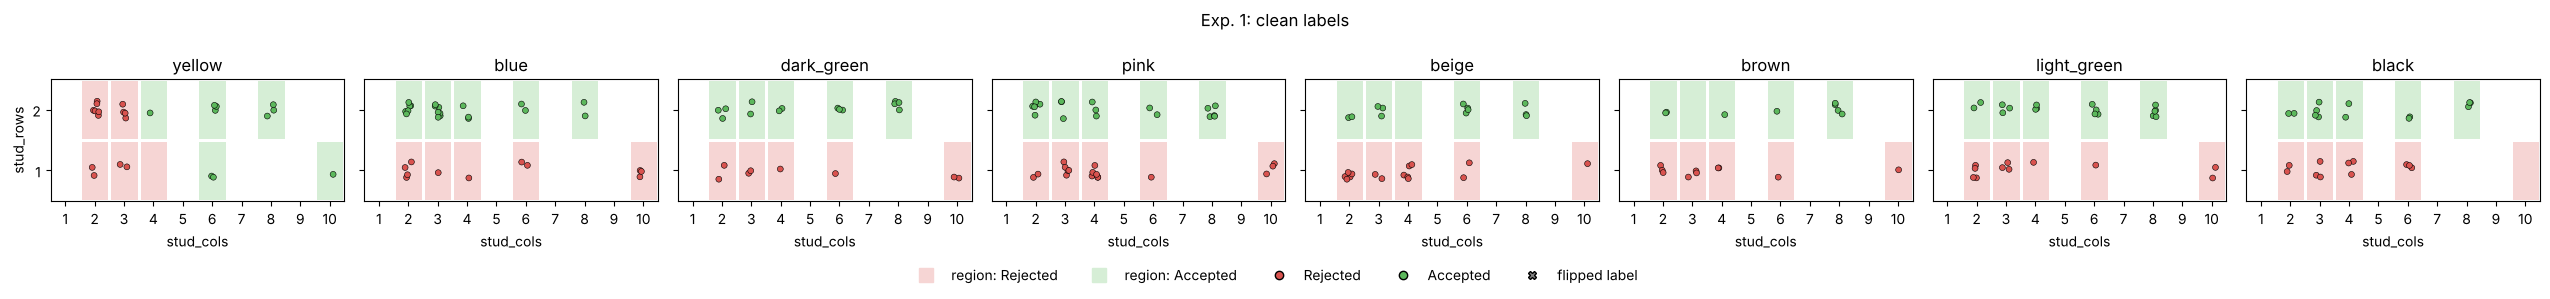

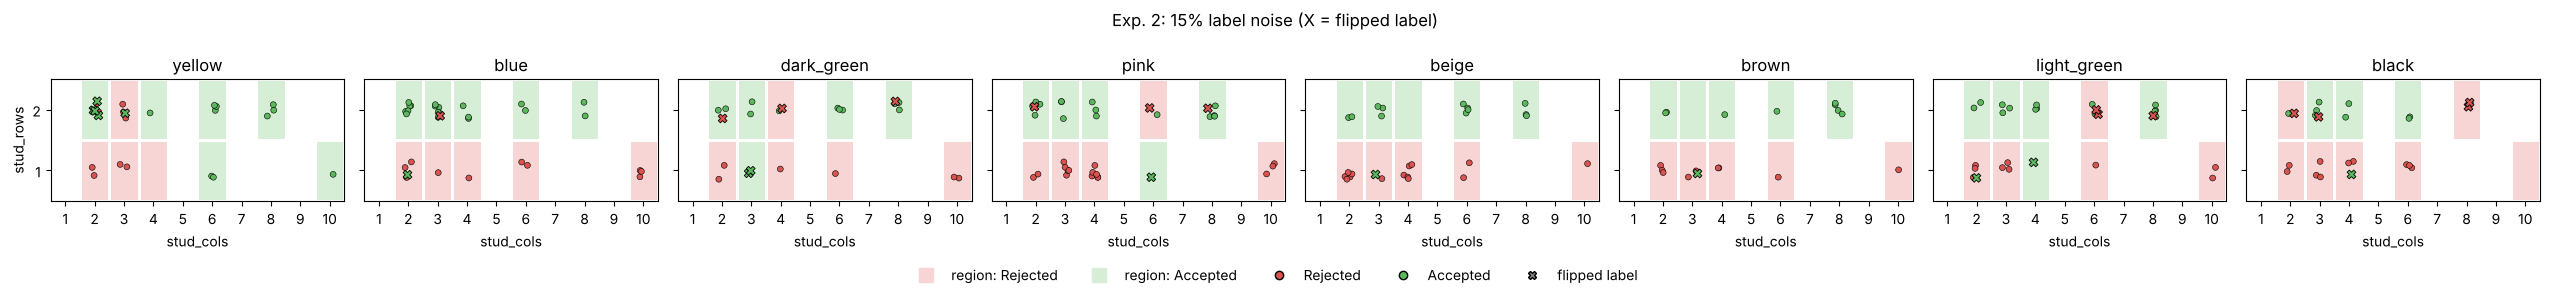

In [7]:
plots.plot_regions(tree1, enc1, train1, title="Exp. 1: clean labels")
plt.show()
plots.plot_regions(tree2, enc2, train2, title="Exp. 2: 15% label noise (X = flipped label)")
plt.show()

### Islands: wrong regions and memorised noisy bricks

In [8]:
# Every brick type that exists, with the builder's true answer
grid = pd.DataFrame([(r, c, col) for col in data.COLOURS for (r, c) in data.BRICK_SHAPES],
                    columns=data.FEATURES)
grid["colour"] = pd.Categorical(grid["colour"], categories=data.COLOURS)
truth = data.builder_rule(grid["stud_rows"], grid["stud_cols"], grid["colour"])

def wrong_types(tree, enc):
    """Brick types where the tree's prediction contradicts the builder's rule."""
    pred = tree.predict(enc.transform(grid[data.FEATURES]))
    return grid[pred != truth]

# Noisy training bricks, and whether the tree memorised their flipped sticker
noisy = train2[train2["flipped"]]
memorised = tree2.predict(enc2.transform(noisy[data.FEATURES])) == noisy[data.TARGET].to_numpy()
noisy_types = set(zip(noisy["stud_rows"], noisy["stud_cols"], noisy["colour"]))

wrong1, wrong2 = wrong_types(tree1, enc1), wrong_types(tree2, enc2)
wrong2 = wrong2.assign(has_flipped_brick=[t in noisy_types for t in
                                          zip(wrong2["stud_rows"], wrong2["stud_cols"], wrong2["colour"])])

print(f"Wrong brick types: Exp. 1 = {len(wrong1)}, Exp. 2 = {len(wrong2)} (of {len(grid)})")
print(f"Noisy training bricks memorised: {memorised.sum()} of {len(noisy)} (the rest lost the vote)")
wrong2

Wrong brick types: Exp. 1 = 1, Exp. 2 = 10 (of 80)
Noisy training bricks memorised: 15 of 28 (the rest lost the vote)


,stud_rows,stud_cols,colour,has_flipped_brick
2,1,4,yellow,False
5,2,2,yellow,True
21,1,3,dark_green,True
27,2,4,dark_green,True
33,1,6,pink,True
38,2,6,pink,True
62,1,4,light_green,True
68,2,6,light_green,True
75,2,2,black,True
79,2,8,black,True


### Trace of one memorised noisy brick

In [9]:
# A noisy brick that the tree isolated in a leaf of its own (an island of size 1)
leaf_ids = tree2.apply(enc2.transform(noisy[data.FEATURES]))
leaf_sizes = tree2.tree_.n_node_samples[leaf_ids]
brick = noisy[memorised & (leaf_sizes == 1)].head(1)

plots.trace(tree2, enc2, brick)
print("Builder's rule says:", plots.CLASS_NAMES[int(brick["accepted_true"].iloc[0])])

Brick: {'stud_rows': 1, 'stud_cols': 4, 'colour': 'light_green'}
  node 0: stud_rows = 1 <= 1.50? yes -> left
  node 1: colour_yellow = 0 <= 0.50? yes -> left
  node 2: stud_cols = 4 <= 8.00? yes -> left
  node 3: colour_dark_green = 0 <= 0.50? yes -> left
  node 4: colour_light_green = 1 <= 0.50? no -> right
  node 30: stud_cols = 4 <= 3.50? no -> right
  node 34: stud_cols = 4 <= 5.00? yes -> left
  leaf 35: 1 training bricks, fractions (Rejected, Accepted) = [0. 1.] -> majority: Accepted
Prediction: Accepted | true label: Accepted
Builder's rule says: Rejected


### Tree diagrams

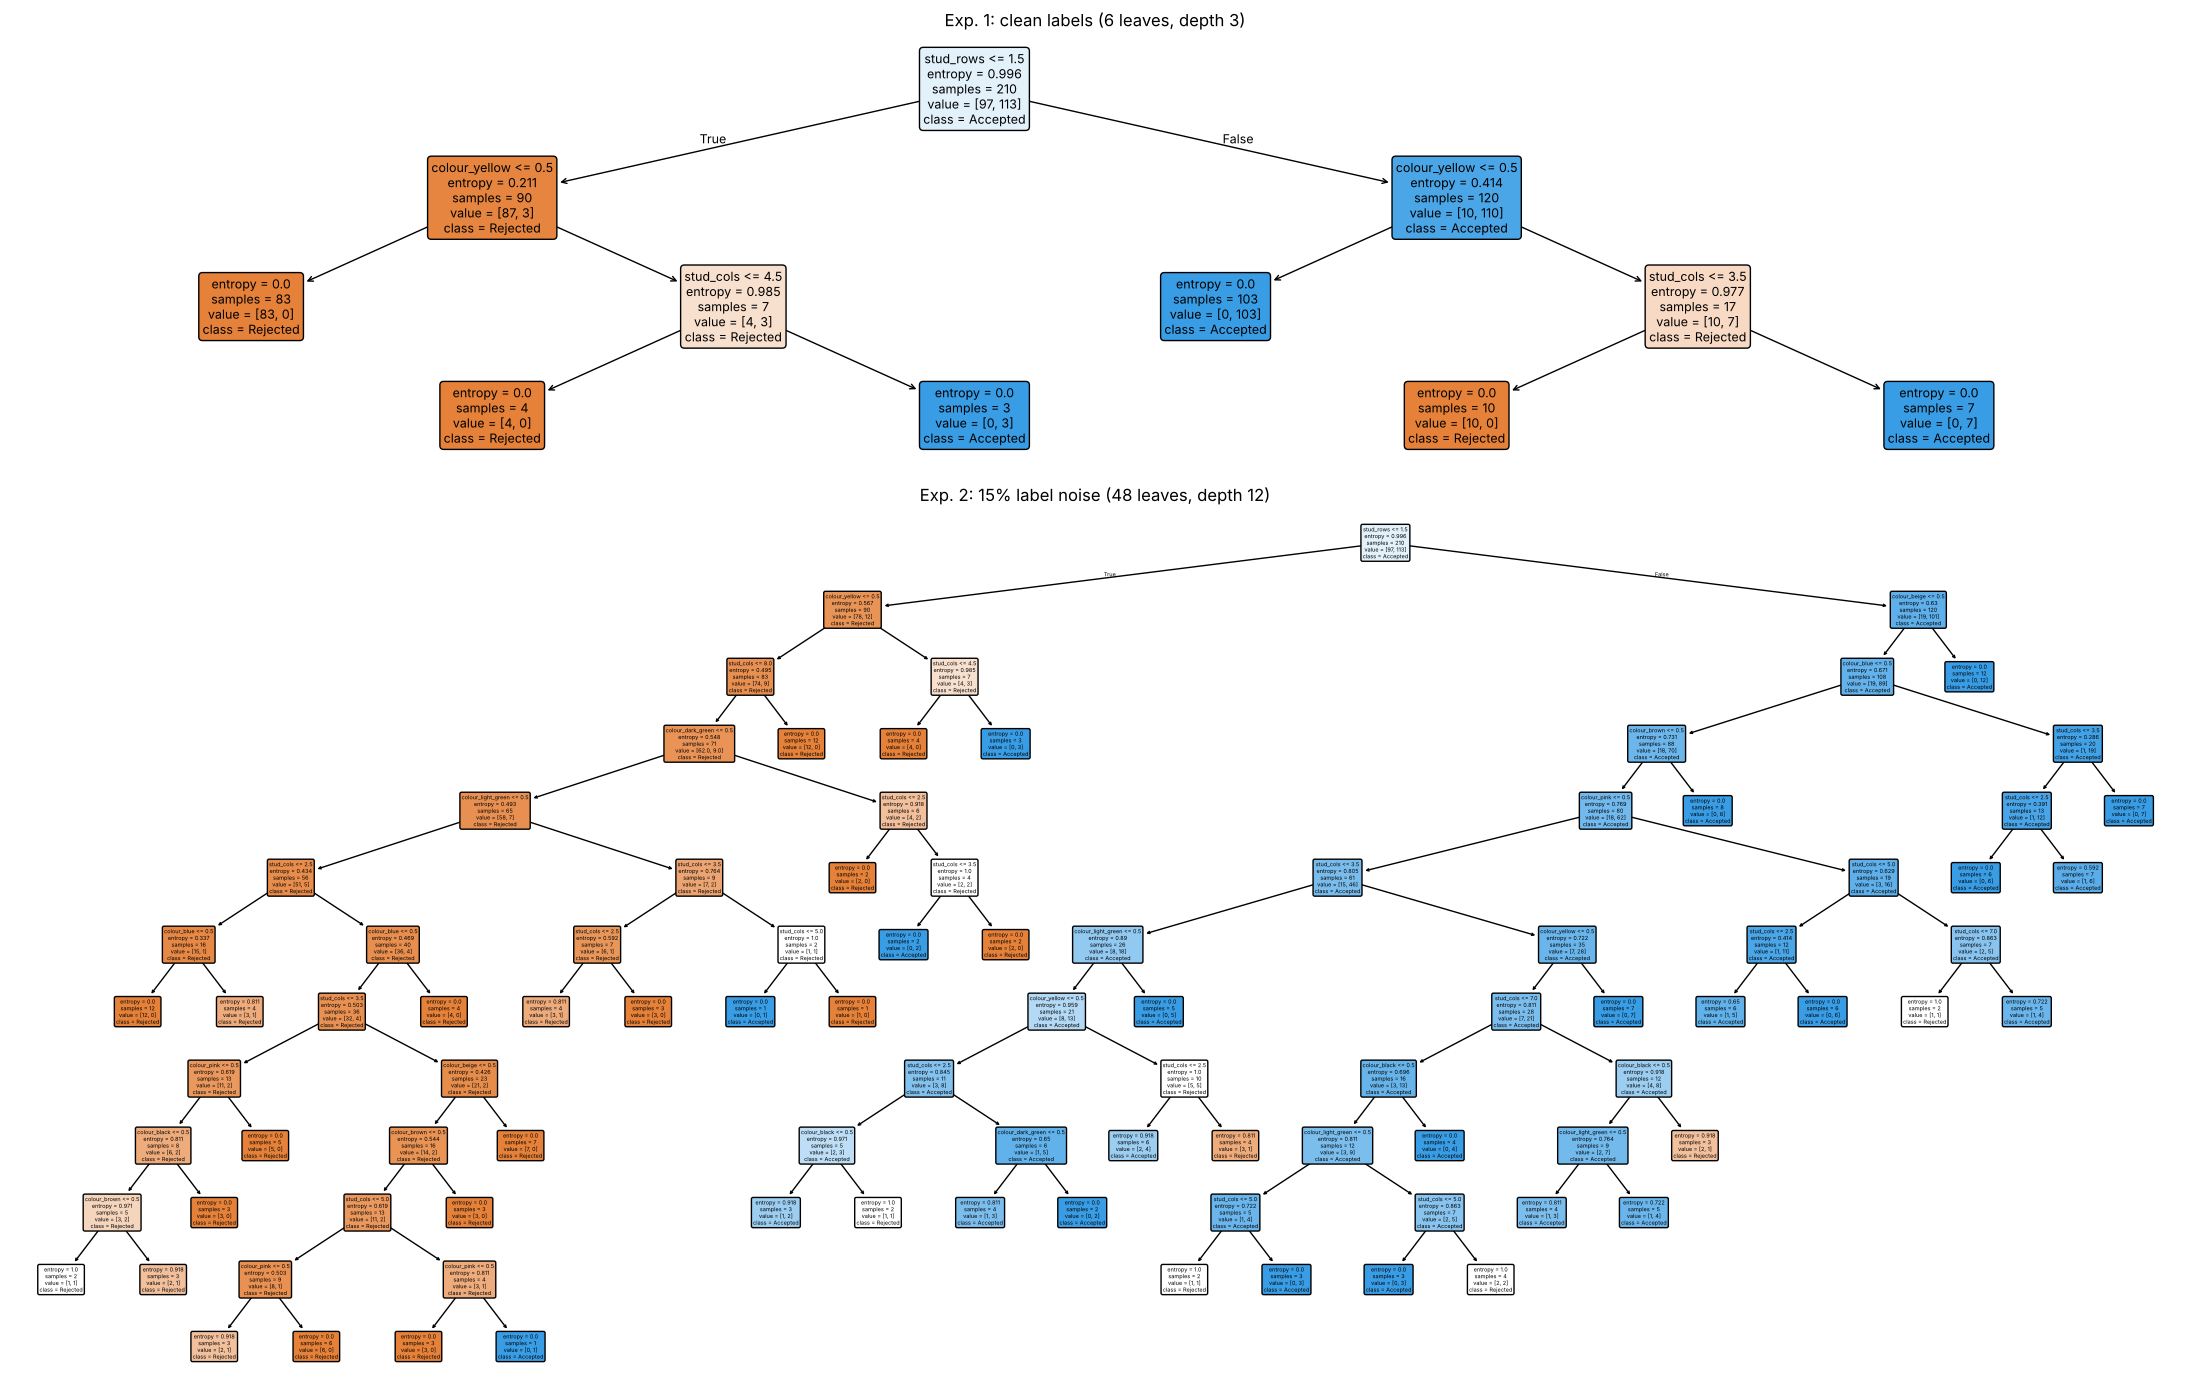

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(22, 14), gridspec_kw={"height_ratios": [1, 2]})
plots.plot_tree(tree1, enc1, ax=axes[0], fontsize=9)
axes[0].set_title(f"Exp. 1: clean labels ({tree1.get_n_leaves()} leaves, depth {tree1.get_depth()})")
plots.plot_tree(tree2, enc2, ax=axes[1], fontsize=4)
axes[1].set_title(f"Exp. 2: 15% label noise ({tree2.get_n_leaves()} leaves, depth {tree2.get_depth()})")
fig.tight_layout()
plt.show()

### Feature importances

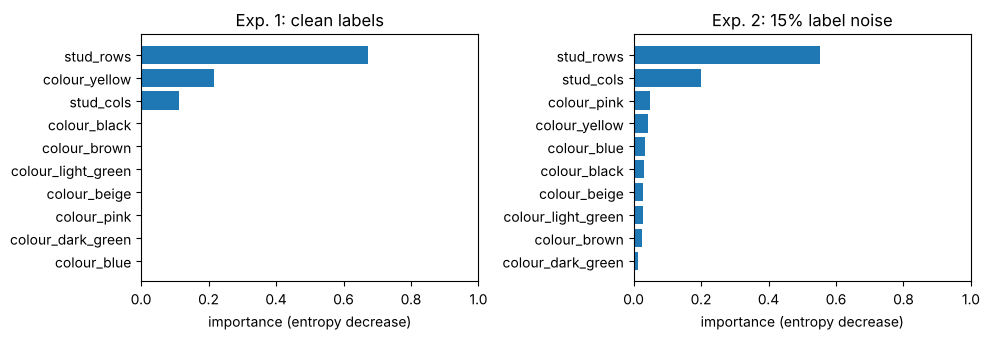

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
plots.plot_importances(tree1, enc1, group_colour=False, ax=axes[0], title="Exp. 1: clean labels")
plots.plot_importances(tree2, enc2, group_colour=False, ax=axes[1], title="Exp. 2: 15% label noise")
fig.tight_layout()
plt.show()

### Robustness across seeds

In [12]:
rows = []
for s in range(10):
    d1 = data.make_data(n=N, noise=0.0, seed=s)
    d2 = data.make_data(n=N, noise=NOISE, seed=s)
    a1, b1 = train_test_split(d1, test_size=TEST_SIZE, stratify=d1["accepted_true"], random_state=s)
    a2, b2 = train_test_split(d2, test_size=TEST_SIZE, stratify=d2["accepted_true"], random_state=s)
    rows.append({"exp": "Exp. 1 (clean)", **fit_and_score(a1, b1, seed=s)[2]})
    rows.append({"exp": "Exp. 2 (15% noise)", **fit_and_score(a2, b2, seed=s)[2]})

seeds = pd.DataFrame(rows).groupby("exp").agg(["mean", "std"]).round(3)
seeds

train acc        test acc (stickers)         \
                        mean    std                mean    std   
exp                                                              
Exp. 1 (clean)         1.000  0.000               1.000  0.000   
Exp. 2 (15% noise)     0.874  0.015               0.794  0.042   

                   test acc (truth)        test macro-F1 (stickers)         \
                               mean    std                     mean    std   
exp                                                                          
Exp. 1 (clean)                1.000  0.000                    1.000  0.000   
Exp. 2 (15% noise)            0.916  0.044                    0.793  0.042   

                   leaves        depth         
                     mean    std  mean    std  
exp                                            
Exp. 1 (clean)        6.0  0.000   3.0  0.000  
Exp. 2 (15% noise)   48.5  4.035  11.6  0.516

**What happened:**

| | Exp. 1 (clean) | Exp. 2 (15% noise) |
|---|---|---|
| Training accuracy | 1.000 | **0.900** |
| Test accuracy (vs stickers) | 0.989 | **0.778** (ceiling 0.811) |
| Test accuracy (vs truth) | 0.989 | **0.900** |
| Leaves / depth | 6 / 3 | **48 / 12** |
| Brick types predicted against the rule | 1 | **10** |
| Std across 10 seeds (test vs truth) | 0 | **0.044** |

**Prediction check:** test accuracy  and tree size predictions were right; training accuracy was partly wrong (expected ~100%, got 0.900)

**Why training accuracy is only 0.900**
- Most of the 76 brick types have several copies, so a flipped brick is usually outvoted by its correct twins in the leaf.
- 13 of the 28 noisy training bricks lost that vote.

**Islands**
- The other 15 noisy bricks were memorised (5 of them through tied leaves, with equal votes for both classes, which scikit-learn resolves to the first class, Rejected).
- 9 of the 10 wrong brick types contain a flipped training brick. The 10th (yellow 1×4) is the same missing-data boundary as in Exp. 1.
- The traced light green 1×4 needs 7 questions instead of 2 and ends in a leaf holding only itself, so every future light green 1×4 will be predicted Accepted, against the rule.
- 22 of the 48 leaves hold 3 training bricks or fewer.

**Feature importances**
- Every colour gains importance, and `colour_yellow` drops from 0.22 to 0.04, below pink.
- The tree spends its questions isolating noisy bricks and loses track of which colour matters.

**Robustness**
- The failure appears in all 10 seeds (48.5 ± 4.0 leaves). Exp. 1 has std 0.
- The tree depends on which bricks happened to be flipped: a first sign of instability.


**Conclusion:** with no depth limit, the tree fits every sticker, including the wrong ones. This is **overfitting**. A depth limit or a minimum leaf size should stop it from isolating single noisy bricks. Exp. 3 tests this, changing one parameter at a time.
